# Residual, enam pilar, tenaga kerja sektoral

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Residual konstruksi D, 2017–2024, penyusun mentah.
--> `logtfp_it` = residual DRS. `logtfp_it_crs` = residual per pekerja.
--> Seri pada gambar adalah log residual.
--> Isi: sampel, between–within, peringkat, enam pilar, tenaga kerja dan investasi sektoral, FGLS grup.
--> Gambar: `01 Data/TFP/output/eda/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "eda"
EVAL = ROOT / "01 Data" / "TFP" / "output" / "eval"
OUT.mkdir(parents=True, exist_ok=True)

NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C", "#ffffff",
)
PULAU_COLOR = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PILAR_COLOR = {
    "pendidikan": NAVY, "equity": TEAL, "institusi": "#062E4C",
    "konektivitas": CYAN, "lingkungan": "#30726A", "keamanan": GRAY,
}
MEGA_COLOR = {"primer": GRAY, "sekunder": NAVY, "tersier": CYAN}

rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "medium",
})

def save(fig, name):
    p = OUT / name
    fig.savefig(p, dpi=140, bbox_inches="tight", facecolor=KERTAS)
    print("wrote", p.relative_to(ROOT))
    return p

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

try:
    display
except NameError:
    def display(x):
        print(x)


In [2]:
SECS = list("ABCDEFGHIJKL") + ["MN", "O", "P", "Q", "RSTU"]
PRIMER, SEKUNDER, TERSIER = ["A", "B"], ["C", "D", "E", "F"], ["G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
EKSTRAKTIF, INDUSTRI, HIJAU_INV = ["A", "B"], ["C", "F"], ["E"]
PADAT_KARYA, PADAT_MODAL = ["A", "C", "F", "G", "I", "P", "Q"], ["B", "D", "H", "J", "K", "L"]
PILAR6 = ["pendidikan", "equity", "institusi", "konektivitas", "lingkungan", "keamanan"]

def _pulau_from_code(c):
    c = int(c)
    if c in (11, 12, 13, 14, 15, 16, 17, 18, 19, 21):
        return "Sumatera"
    if c in (31, 32, 33, 34, 35, 36):
        return "Jawa"
    if c in (51, 52, 53):
        return "Bali-Nusra"
    if c in (61, 62, 63, 64, 65):
        return "Kalimantan"
    if c in (71, 72, 73, 74, 75, 76):
        return "Sulawesi"
    return "Maluku-Papua"

def load_eval_panel():
    for cand in [EVAL / "eval_panel_2017_2025.xlsx", EVAL / "eval_panel.dta", EVAL / "eval_panel.xlsx"]:
        if cand.exists():
            print("load", cand.relative_to(ROOT))
            if cand.suffix == ".dta":
                d = pd.read_stata(cand)
            else:
                d = pd.read_excel(cand, sheet_name="panel")
            d["Pulau"] = d["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
            return d
    print("eval_panel belum ada — merakit panel deskriptif dari konstruksi + Luaran 2 + Sheet1")
    return build_panel_fallback()

def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(ddof=1)
    if sd == 0 or pd.isna(sd):
        return s * np.nan
    return (s - s.mean()) / sd

def build_panel_fallback():
    tfp = pd.read_excel(ROOT / "01 Data" / "TFP" / "output" / "konstruksi" / "TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
    xlsx = ROOT / "01 Data" / "TFP" / "processed" / "Dataset Agregasi Provinsi Penyetaraan Satuan Miliar Float (keamanan).xlsx"
    if not xlsx.exists():
        xlsx = ROOT / "01 Data" / "TFP" / "AI-Pak_Yudis" / "Dataset Agregasi Provinsi Penyetaraan Satuan Miliar Float (keamanan).xlsx"
    lu = pd.read_excel(xlsx, sheet_name="Analisis Luaran 2")
    s1 = pd.read_excel(xlsx, sheet_name="Sheet1")
    peta = pd.read_csv(ROOT / "01 Data" / "BKPM" / "processed" / "Dataset Provinsi(prov_name).csv")
    peta = peta.dropna(subset=["Code_Prov"]).drop_duplicates("Code_Prov")
    peta["Pulau"] = peta["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
    lu = lu[(lu.Year >= 2017) & (lu.Year <= 2025)].copy()
    s1 = s1[(s1.Year >= 2017) & (s1.Year <= 2025)].copy()
    keep_s1 = ["Code_Prov", "Year", "Exp_Prov", "Inc_Prov"] + [f"{s}_PMA" for s in SECS] + [f"{s}_PMDN" for s in SECS] + [f"{s}_ADHK" for s in SECS]
    d = tfp.merge(lu.drop(columns=["logtfp_it", "logtfp_it_crs"], errors="ignore"), on=["Code_Prov", "Year"], how="left")
    d = d.merge(s1[keep_s1], on=["Code_Prov", "Year"], how="left")
    d = d.merge(peta[["Code_Prov", "Pulau"]], on="Code_Prov", how="left")
    d["Pulau"] = d["Pulau"].fillna(d["Code_Prov"].map(_pulau_from_code))
    d["lama_sekolah_mean"] = d["Educ_Prov"]
    d["lama_sekolah_harapan"] = d["Heduc_Prov"]
    d["ipm"] = d["IPM_Prov_Nm"]
    d["gini"] = d["Gini_Prov"]
    d["p0"] = d["P0_Prov"]
    d["p1"] = d["Ikk_Prov"]
    d["equality"] = -d["gini"]
    d["upah_rata"] = d["Upah_Agr_Prov"]
    d["rasio_pad"] = d["RasioPAD_Prov"]
    d["apbd_belanja"] = d["Belanja_APBD_Prov"]
    d["apbd_serapan"] = d["Serapan_Prov"]
    d["indeks_demokrasi"] = d["IDI_Prov2"]
    d["indeks_lingkungan"] = d["IKLH_Prov"]
    d["indeks_hijau"] = d["Hijau_Prov"]
    d["indeks_biru"] = d["Biru_Prov"]
    d["pengeluaran_kapita"] = d["Exp_Prov"]
    d["pendapatan_kapita"] = d["Inc_Prov"]
    d["tk_total"] = d[[f"{s}_TenagaKerja" for s in SECS]].sum(axis=1)
    for s in SECS:
        d[f"tk_{s}"] = d[f"{s}_TenagaKerja"]
        d[f"inv_{s}"] = d[f"{s}_PMA"].fillna(0).clip(lower=0) + d[f"{s}_PMDN"].fillna(0).clip(lower=0)
        d[f"share_tk_{s}"] = d[f"tk_{s}"] / d["tk_total"]
        d[f"share_pdrb_{s}"] = d[f"{s}_ADHK"] / d["pdrb_adhk"]
    d["inv_total"] = d[[f"inv_{s}" for s in SECS]].sum(axis=1)
    for s in SECS:
        d[f"share_inv_{s}"] = np.where(d["inv_total"] > 0, d[f"inv_{s}"] / d["inv_total"], 0)
    def bundle(keys, name):
        d[f"share_tk_{name}"] = d[[f"share_tk_{s}" for s in keys]].sum(axis=1)
        d[f"share_inv_{name}"] = d[[f"share_inv_{s}" for s in keys]].sum(axis=1)
        d[f"share_pdrb_{name}"] = d[[f"share_pdrb_{s}" for s in keys]].sum(axis=1)
    bundle(PRIMER, "primer"); bundle(SEKUNDER, "sekunder"); bundle(TERSIER, "tersier")
    bundle(EKSTRAKTIF, "ekstraktif"); bundle(INDUSTRI, "industri"); bundle(HIJAU_INV, "hijau_inv")
    bundle(PADAT_KARYA, "padat_karya"); bundle(PADAT_MODAL, "padat_modal")
    d["inv_sawit"] = d["inv_A"]
    d["share_inv_A"] = d["share_inv_A"]
    d["dominan_tk"] = np.select(
        [d["share_tk_primer"] >= d[["share_tk_sekunder", "share_tk_tersier"]].max(axis=1),
         d["share_tk_sekunder"] >= d[["share_tk_primer", "share_tk_tersier"]].max(axis=1)],
        ["primer", "sekunder"], default="tersier")
    z_educ = zscore(np.log(d["lama_sekolah_mean"] + 1))
    z_heduc = zscore(np.log(d["lama_sekolah_harapan"] + 1))
    z_kampus = zscore(d["APK_Tersier"])
    z_sma = zscore(d["APK_Sekunder2"])
    d["pilar_pendidikan"] = zscore(pd.concat([z_educ, z_heduc, z_sma, z_kampus], axis=1).mean(axis=1))
    d["pilar_equity"] = zscore(pd.concat([
        zscore(np.log(d["ipm"] + 1)), zscore(-np.log(d["p1"] + 1)),
        zscore(d["equality"]), zscore(np.log(d["upah_rata"] + 1)),
        zscore(np.log(d["indeks_demokrasi"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_institusi"] = zscore(pd.concat([
        zscore(-np.log(d["PDBDeflator"] + 1)), zscore(np.log(d["rasio_pad"] + 1)),
        zscore(np.log(d["apbd_belanja"] + 1)), zscore(np.log(d["apbd_serapan"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_konektivitas"] = zscore(pd.concat([
        zscore(np.log(d["Road_Prov_National"] + 1)), zscore(np.log(d["Cargo_Kapal_Prov"] + 1)),
        zscore(np.log(d["Cargo_KA_Prov"] + 1)), zscore(np.log(d["Airpot_Logis"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_lingkungan"] = zscore(pd.concat([
        zscore(np.log(d["indeks_lingkungan"] + 1)), zscore(np.log(d["indeks_hijau"] + 1)),
        zscore(np.log(d["indeks_biru"] + 1)),
    ], axis=1).mean(axis=1))
    d["pilar_keamanan"] = zscore(pd.concat([
        zscore(-np.log(d["CrimeRisk_BPS"] + 1)), zscore(-np.log(d["CR_Prov"] + 1)),
    ], axis=1).mean(axis=1))
    d["idx_solow"] = zscore(d[["pilar_pendidikan", "pilar_equity", "pilar_institusi"]].mean(axis=1))
    d["idx_hard"] = zscore(d[["pilar_konektivitas", "pilar_keamanan"]].mean(axis=1))
    d["idx_fiskal"] = zscore(pd.concat([
        zscore(d["rasio_pad"]), zscore(d["apbd_serapan"]), zscore(np.log(d["apbd_belanja"] + 1)),
    ], axis=1).mean(axis=1))
    d["log_kl"] = d["log_K"] - d["log_L"]
    for col in [f"pilar_{p}" for p in PILAR6] + ["idx_solow", "idx_hard", "idx_fiskal",
                "logtfp_it", "logtfp_it_crs", "indeks_hijau", "ipm", "gini", "p0",
                "share_tk_primer", "share_tk_sekunder", "share_tk_ekstraktif",
                "share_tk_C", "share_inv_A", "share_inv_C", "rasio_pad", "log_kl"]:
        d[f"m_{col}"] = d.groupby("Code_Prov")[col].transform("mean")
    # top5 / bot5 from province means
    pm = d.drop_duplicates("Code_Prov")
    for p in PILAR6:
        order = pm.sort_values(f"m_pilar_{p}", ascending=False)["Code_Prov"]
        d[f"top5_{p}"] = d["Code_Prov"].isin(order.head(5)).astype(int)
        d[f"bot5_{p}"] = d["Code_Prov"].isin(order.tail(5)).astype(int)
    med_f = pm["m_idx_fiskal"].median()
    d["d_high_fiskal"] = (d["m_idx_fiskal"] >= med_f).astype(int)
    d["d_sawit"] = (d["m_share_inv_A"] >= pm["m_share_inv_A"].quantile(0.75)).astype(int)
    d["d_ekstraktif"] = (d["m_share_tk_ekstraktif"] >= pm["m_share_tk_ekstraktif"].quantile(0.75)).astype(int)
    d["d_hilir"] = (d["m_share_tk_C"] >= pm["m_share_tk_C"].quantile(0.75)).astype(int)
    d["Pre_Prov"] = d["Pre_Prov"].astype(str).str.strip()
    return d

d = load_eval_panel()
d["Pre_Prov"] = d["Pre_Prov"].astype(str).str.strip()
if "Pulau" not in d.columns:
    d["Pulau"] = d["Code_Prov"].map(_pulau_from_code)
num_cols = d.select_dtypes(include=[np.number]).columns.tolist()
keep_first = [c for c in ["Pre_Prov", "Pulau", "dominan_tk"] if c in d.columns]
agg = {c: "first" for c in keep_first}
for c in num_cols:
    if c in ("Code_Prov", "Year"):
        continue
    agg[c] = "mean"
pm = d.groupby("Code_Prov", as_index=False).agg(agg)
pm["Pulau"] = pm["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})
show_cols = [c for c in ["Code_Prov", "Pre_Prov", "Pulau", "logtfp_it_crs", "idx_solow",
                         "idx_fiskal", "share_tk_primer", "indeks_hijau"] if c in pm.columns]
print(d.shape, "panel", pm.shape, "provinsi", int(d.Year.min()), int(d.Year.max()))
display(pm[show_cols].sort_values("logtfp_it_crs", ascending=False).head(8))


load 01 Data/TFP/output/eval/eval_panel_2017_2025.xlsx
04_eda_deskriptif.ipynb:2:158: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
(306, 616) panel (34, 614) provinsi 2017 2025


    Code_Prov             Pre_Prov         Pulau  logtfp_it_crs  idx_solow  idx_fiskal  share_tk_primer  indeks_hijau
10         31          DKI Jakarta          Jawa      -0.099577   1.722866    1.351689         0.007974     26.137085
22         64     Kalimantan Timur    Kalimantan      -0.124713   2.170773    0.843234         0.270951     82.277114
32         91          Papua Barat  Maluku-Papua      -0.331663  -0.931945   -0.380982         0.354516    100.000000
23         65     Kalimantan Utara    Kalimantan      -0.414222  -0.165192   -1.168401         0.328861     99.928889
3          14                 Riau      Sumatera      -0.472358   0.183518    0.198788         0.386972     50.612223
9          21             Kep.Riau      Sumatera      -0.548341   0.598088   -0.328549         0.085869     61.236710
4          15                Jambi      Sumatera      -0.691346  -0.173740   -0.416332         0.482009     54.228233
8          19  Kep.Bangka Belitung      Sumatera      -0

## Residual: sampel, between/within, jalur nasional


N = 306 | provinsi = 34 | tahun = [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
wrote 01 Data/TFP/output/eda/eda1_national_path.png


               count          mean           std          min           50%           max
log_Y          306.0  1.204580e+01  1.134600e+00      10.0549  1.188640e+01  1.463720e+01
log_K          306.0  1.088230e+01  1.141100e+00       8.8748  1.069940e+01  1.364830e+01
log_L          306.0  1.453440e+01  1.008800e+00      12.6464  1.449850e+01  1.694410e+01
logtfp_it      306.0  5.027500e+00  5.486000e-01       3.9336  4.955300e+00  6.380300e+00
logtfp_it_crs  306.0 -9.033000e-01  3.353000e-01      -1.7067 -9.444000e-01 -2.900000e-03
pdrb_adhk      306.0  3.440219e+05  4.887270e+05   23269.0800  1.452831e+05  2.274436e+06
pmtb_adhk      306.0  1.066398e+05  1.545232e+05    7149.6600  4.433132e+04  8.460043e+05
labours_total  306.0  3.679564e+06  5.161104e+06  310642.0000  1.979834e+06  2.284194e+07


                DRS logtfp_it  CRS logtfp_it_crs   log Y
overall                0.5486             0.3353  1.1346
between                0.5509             0.3349  1.1430
within                 0.0739             0.0568  0.1228
pangsa_between         1.0083             0.9975  1.0149


     logtfp_it         logtfp_it_crs            log_Y        
          mean     std          mean     std     mean     std
Year                                                         
2017    4.9441  0.5554       -0.9475  0.3345  11.8877  1.1599
2018    4.9723  0.5509       -0.9340  0.3321  11.9425  1.1571
2019    4.9878  0.5610       -0.9282  0.3345  11.9884  1.1562
2020    4.9858  0.5625       -0.9310  0.3434  11.9756  1.1485
2021    5.0038  0.5585       -0.9235  0.3395  12.0163  1.1437
2022    5.0382  0.5577       -0.9000  0.3385  12.0718  1.1396
2023    5.0718  0.5469       -0.8793  0.3357  12.1242  1.1367
2024    5.1017  0.5431       -0.8626  0.3398  12.1761  1.1334
2025    5.1419  0.5349       -0.8240  0.3402  12.2293  1.1266


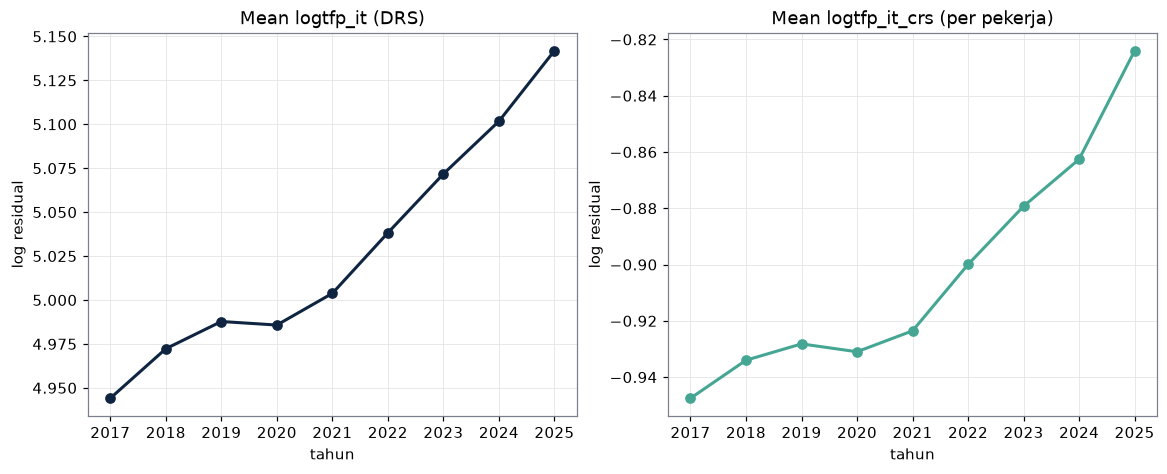

In [3]:
cols = [c for c in ["log_Y", "log_K", "log_L", "logtfp_it", "logtfp_it_crs",
                    "pdrb_adhk", "pmtb_adhk", "labours_total"] if c in d.columns]
print("N =", len(d), "| provinsi =", d.Code_Prov.nunique(),
      "| tahun =", sorted(d.Year.astype(int).unique()))
display(d[cols].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(4))

def xt_sd(s, gid):
    overall = s.std(ddof=1)
    between = s.groupby(gid).mean().std(ddof=1)
    within = (s - s.groupby(gid).transform("mean")).std(ddof=1)
    return pd.Series({"overall": overall, "between": between, "within": within,
                      "pangsa_between": between**2 / overall**2})

xt = pd.DataFrame({
    "DRS logtfp_it": xt_sd(d.logtfp_it, d.Code_Prov),
    "CRS logtfp_it_crs": xt_sd(d.logtfp_it_crs, d.Code_Prov),
    **({"log Y": xt_sd(d.log_Y, d.Code_Prov)} if "log_Y" in d.columns else {}),
})
display(xt.round(4))

by_year = (d.groupby("Year")[[c for c in ["logtfp_it", "logtfp_it_crs", "log_Y"] if c in d.columns]]
             .agg(["mean", "std"]).round(4))
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)
y = d.groupby("Year")[["logtfp_it", "logtfp_it_crs"]].mean()
axes[0].plot(y.index, y.logtfp_it, color=NAVY, marker="o", lw=2)
axes[0].set_title("Mean logtfp_it (DRS)")
axes[0].set_xlabel("tahun"); axes[0].set_ylabel("log residual")
axes[1].plot(y.index, y.logtfp_it_crs, color=TEAL, marker="o", lw=2)
axes[1].set_title("Mean logtfp_it_crs (per pekerja)")
axes[1].set_xlabel("tahun"); axes[1].set_ylabel("log residual")
for ax in axes:
    ax.set_xticks(sorted(d.Year.unique()))
save(fig, "eda1_national_path.png")
plt.show()


## Peringkat provinsi, DRS dan CRS


wrote 01 Data/TFP/output/eda/eda1_rank_drs.png
wrote 01 Data/TFP/output/eda/eda1_rank_crs.png


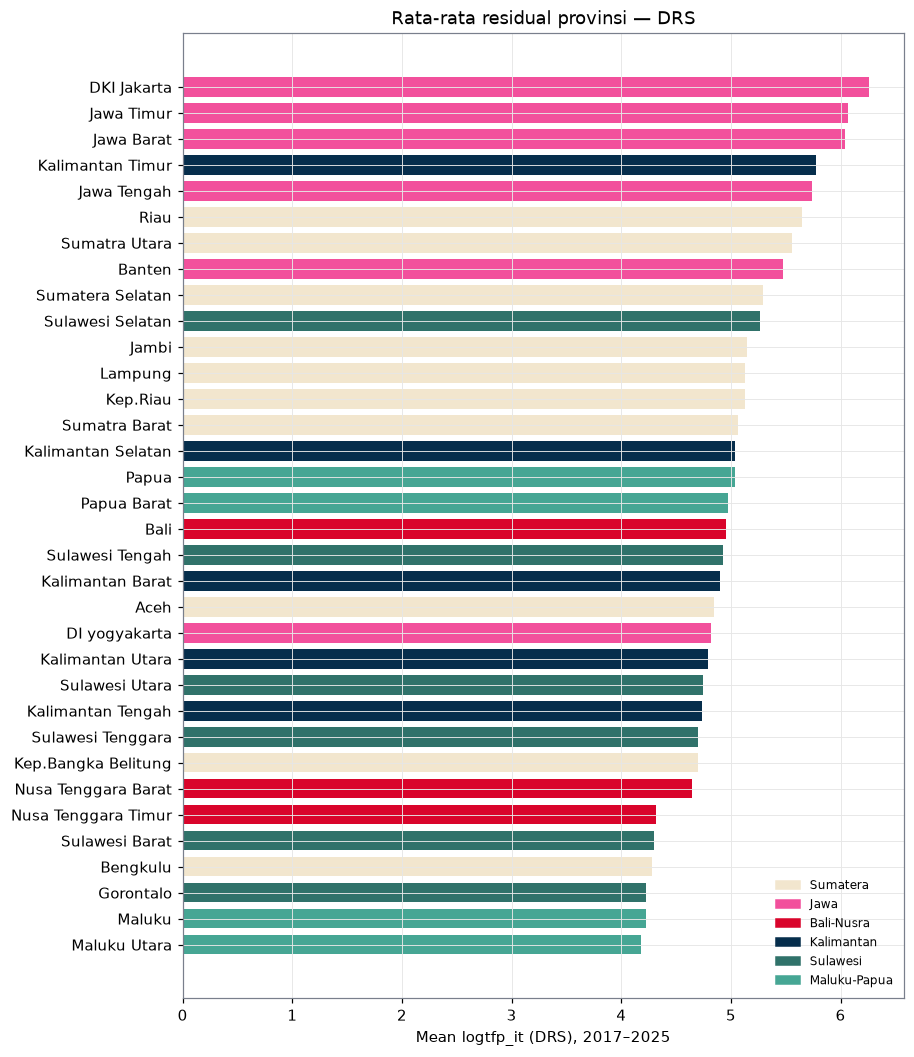

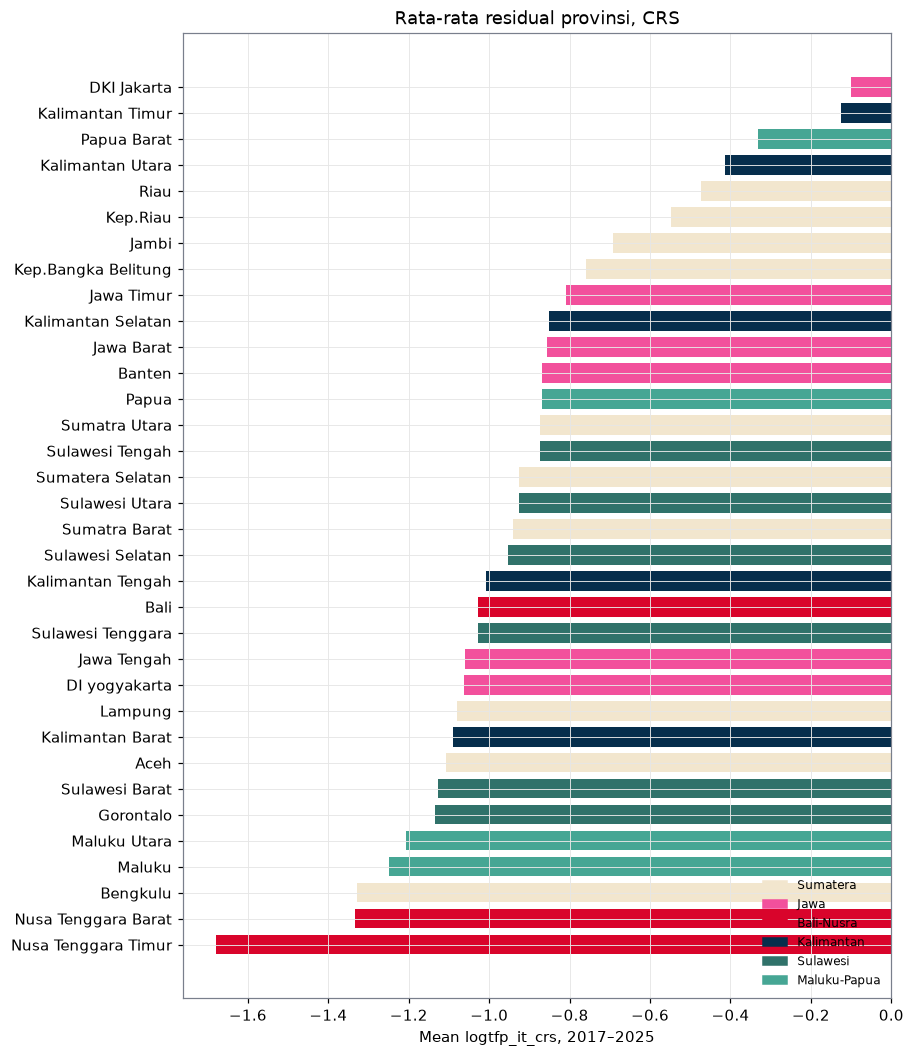

In [4]:
rk = pm.copy()
rk["drs"] = rk["logtfp_it"]
rk["crs"] = rk["logtfp_it_crs"]

fig, ax = plt.subplots(figsize=(8.2, 9.5), constrained_layout=True)
rk1 = rk.sort_values("drs")
ax.barh(rk1.Pre_Prov, rk1.drs, color=rk1.Pulau.map(PULAU_COLOR), height=0.75)
ax.set_xlabel("Mean logtfp_it (DRS), 2017–2025")
ax.set_title("Rata-rata residual provinsi — DRS")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in PULAU_COLOR.items()]
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=8)
save(fig, "eda1_rank_drs.png")
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 9.5), constrained_layout=True)
rk2 = rk.sort_values("crs")
ax.barh(rk2.Pre_Prov, rk2.crs, color=rk2.Pulau.map(PULAU_COLOR), height=0.75)
ax.set_xlabel("Mean logtfp_it_crs, 2017–2025")
ax.set_title("Rata-rata residual provinsi, CRS")
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=8)
save(fig, "eda1_rank_crs.png")
plt.show()


## Skala dan sebaran pulau


corr DRS, log Y = 0.969
corr CRS, log Y = 0.448
wrote 01 Data/TFP/output/eda/eda1_scale_scatter.png
wrote 01 Data/TFP/output/eda/eda1_island_box.png


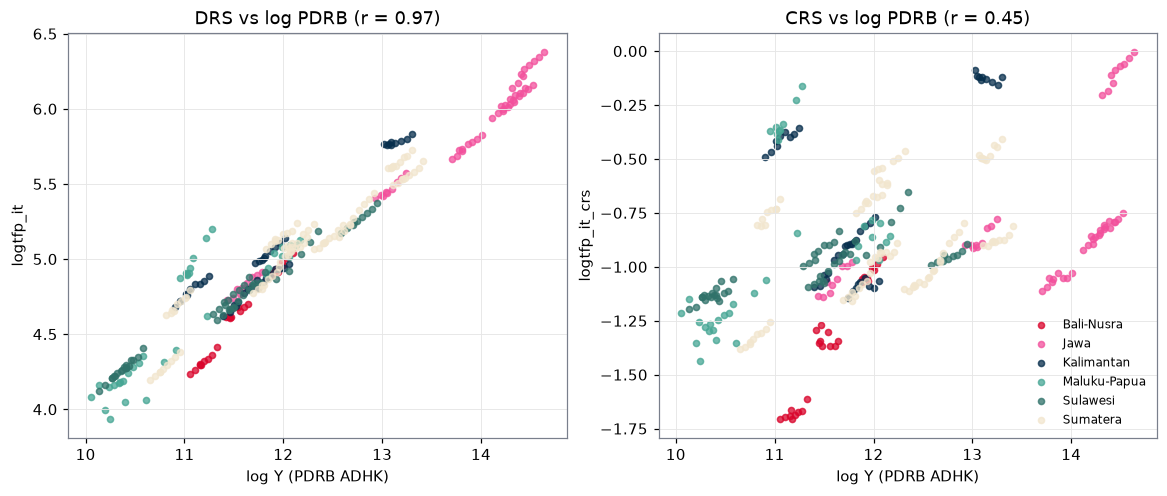

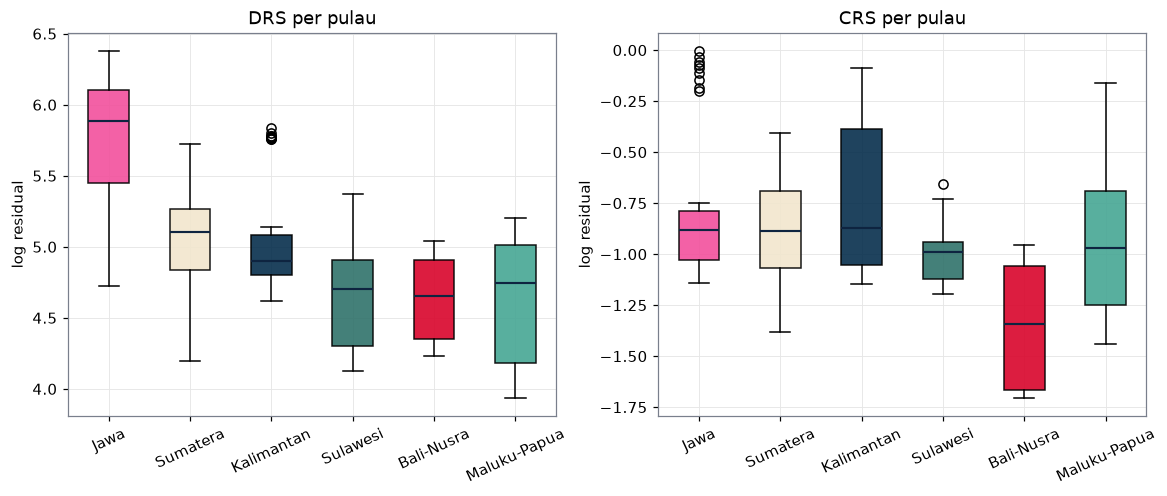

In [5]:
ycol_y = "log_Y" if "log_Y" in d.columns else None
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
if ycol_y is not None:
    r_drs = d.logtfp_it.corr(d[ycol_y])
    r_crs = d.logtfp_it_crs.corr(d[ycol_y])
    pairs = [
        (axes[0], "logtfp_it", f"DRS vs log PDRB (r = {r_drs:.2f})"),
        (axes[1], "logtfp_it_crs", f"CRS vs log PDRB (r = {r_crs:.2f})"),
    ]
    for ax, ycol, title in pairs:
        for pulau, g in d.groupby("Pulau"):
            ax.scatter(g[ycol_y], g[ycol], s=16, alpha=0.75,
                       color=PULAU_COLOR.get(pulau, GRAY), label=pulau)
        ax.set_xlabel("log Y (PDRB ADHK)")
        ax.set_ylabel(ycol)
        ax.set_title(title)
    axes[1].legend(frameon=False, fontsize=8, loc="best")
    print("corr DRS, log Y =", round(r_drs, 3))
    print("corr CRS, log Y =", round(r_crs, 3))
else:
    axes[0].set_title("Log output")
save(fig, "eda1_scale_scatter.png")
plt.show()

order = ["Jawa", "Sumatera", "Kalimantan", "Sulawesi", "Bali-Nusra", "Maluku-Papua"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
for ax, col, title in [
    (axes[0], "logtfp_it", "DRS per pulau"),
    (axes[1], "logtfp_it_crs", "CRS per pulau"),
]:
    data = [d.loc[d.Pulau == p, col].dropna().values for p in order]
    kw = dict(patch_artist=True, medianprops={"color": NAVY, "lw": 1.4})
    try:
        bp = ax.boxplot(data, tick_labels=order, **kw)
    except TypeError:
        bp = ax.boxplot(data, labels=order, **kw)
    for patch, p in zip(bp["boxes"], order):
        patch.set_facecolor(PULAU_COLOR[p])
        patch.set_alpha(0.9)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("log residual")
save(fig, "eda1_island_box.png")
plt.show()


## Penyusun determinan (z)


wrote 01 Data/TFP/output/eda/eda1_z_corr.png
wrote 01 Data/TFP/output/eda/eda1_between_scatter.png


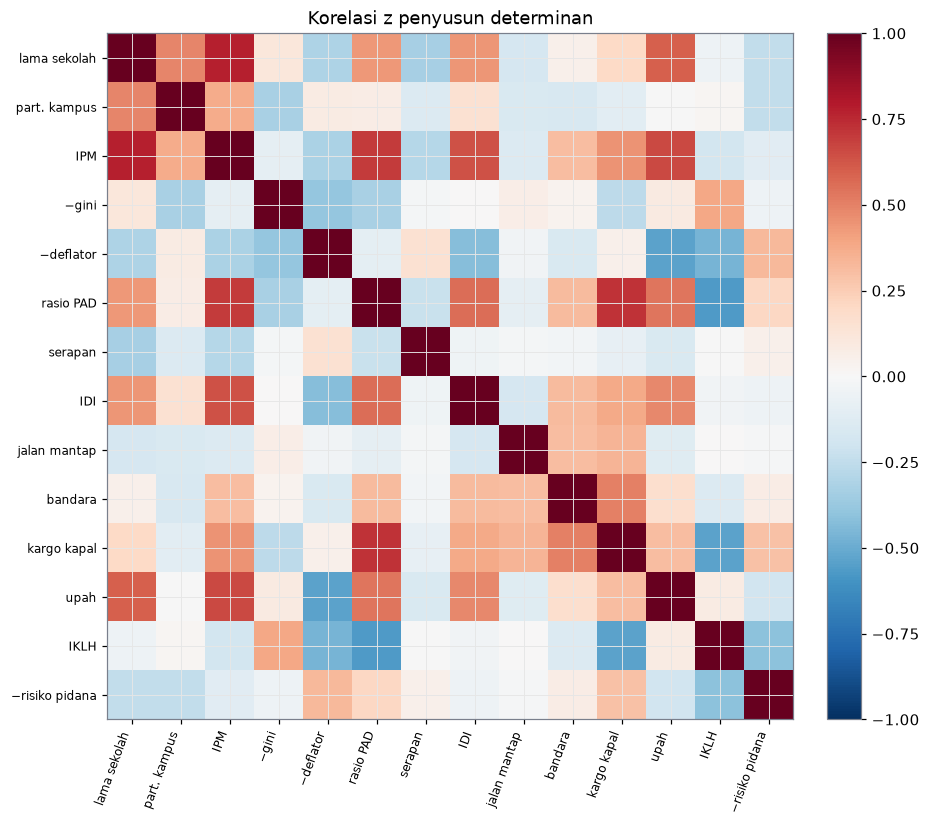

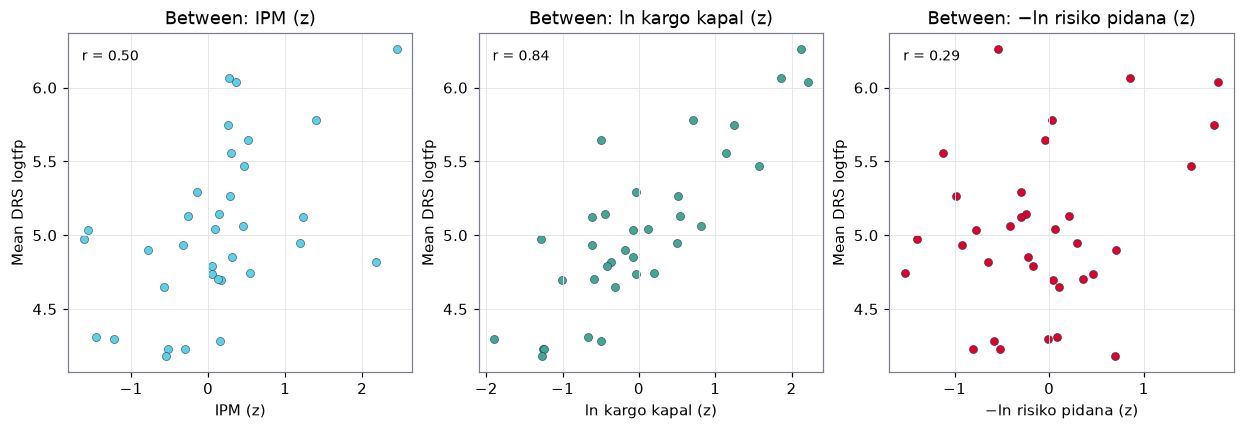

In [6]:
prefer = [
    "z_ln_lama_sekolah_mean", "z_logit_partisipasi_kampus", "z_ln_ipm", "z_equality",
    "z_price", "z_ln_rasio_pad", "z_ln_apbd_serapan", "z_ln_indeks_demokrasi",
    "z_ln_jalan_mantap", "z_ln_airport_logistik", "z_ln_kargo_kapal",
    "z_ln_upah_rata", "z_ln_indeks_lingkungan", "z_ln_crime_risk",
]
x_z = [c for c in prefer if c in d.columns]
if len(x_z) < 6:
    x_z = [c for c in d.columns if c.startswith("z_ln_") or c.startswith("z_logit")
           or c in ("z_price", "z_equality", "z_gini")][:14]
lab_z = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_logit_partisipasi_kampus": "part. kampus",
    "z_ln_ipm": "IPM",
    "z_equality": "−gini",
    "z_price": "−deflator",
    "z_ln_rasio_pad": "rasio PAD",
    "z_ln_apbd_serapan": "serapan",
    "z_ln_indeks_demokrasi": "IDI",
    "z_ln_jalan_mantap": "jalan mantap",
    "z_ln_airport_logistik": "bandara",
    "z_ln_kargo_kapal": "kargo kapal",
    "z_ln_upah_rata": "upah",
    "z_ln_indeks_lingkungan": "IKLH",
    "z_ln_crime_risk": "−risiko pidana",
}

R = d[x_z].corr()
fig, ax = plt.subplots(figsize=(8.8, 7.4), constrained_layout=True)
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(x_z)))
ax.set_yticks(range(len(x_z)))
short = [lab_z.get(c, c.replace("z_", "").replace("ln_", "")) for c in x_z]
ax.set_xticklabels(short, rotation=70, ha="right", fontsize=8)
ax.set_yticklabels(short, fontsize=8)
ax.set_title("Korelasi z penyusun determinan")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
save(fig, "eda1_z_corr.png")
plt.show()

pairs = [
    ("z_ln_ipm", "IPM (z)", CYAN),
    ("z_ln_kargo_kapal", "ln kargo kapal (z)", TEAL),
    ("z_ln_crime_risk", "−ln risiko pidana (z)", RED),
]
pairs = [(c, lab, col) for c, lab, col in pairs if c in pm.columns]
fig, axes = plt.subplots(1, max(len(pairs), 1), figsize=(11.2, 3.8), constrained_layout=True)
if len(pairs) == 1:
    axes = [axes]
if not pairs:
    print("kolom between scatter tidak ada")
else:
    for ax, (x, lab, col) in zip(axes, pairs):
        ax.scatter(pm[x], pm["logtfp_it"], s=28, color=col, edgecolor=NAVY, lw=0.3)
        ax.set_xlabel(lab)
        ax.set_ylabel("Mean DRS logtfp")
        ax.set_title(f"Between: {lab}")
        r = pm[x].corr(pm["logtfp_it"])
        ax.text(0.04, 0.92, f"r = {r:.2f}", transform=ax.transAxes, fontsize=9)
save(fig, "eda1_between_scatter.png")
plt.show()


## Profil ujung pilar


pilar         ujung
equity        bot5     Papua, Papua Barat, Nusa Tenggara Timur, Goron...
              top5     DKI Jakarta, Kalimantan Timur, Kep.Bangka Beli...
institusi     bot5     Kalimantan Utara, Maluku Utara, Maluku, Bengku...
              top5     Jawa Barat, Jawa Tengah, Jawa Timur, Banten, K...
keamanan      bot5     Sulawesi Utara, Sumatra Utara, DI yogyakarta, ...
              top5     Jawa Barat, Banten, Jawa Tengah, Papua, Maluku...
konektivitas  bot5     Sulawesi Barat, Gorontalo, Maluku Utara, Sulaw...
              top5     Jawa Barat, Jawa Timur, Jawa Tengah, DKI Jakar...
lingkungan    bot5     DKI Jakarta, Jawa Barat, DI yogyakarta, Banten...
              top5     Papua Barat, Papua, Kalimantan Utara, Sulawesi...
pendidikan    bot5     Papua, Kep.Bangka Belitung, Kalimantan Barat, ...
              top5     DI yogyakarta, Kalimantan Timur, Maluku, Aceh,...
wrote 01 Data/TFP/output/eda/eda1_rqA_topbot_pilar.png


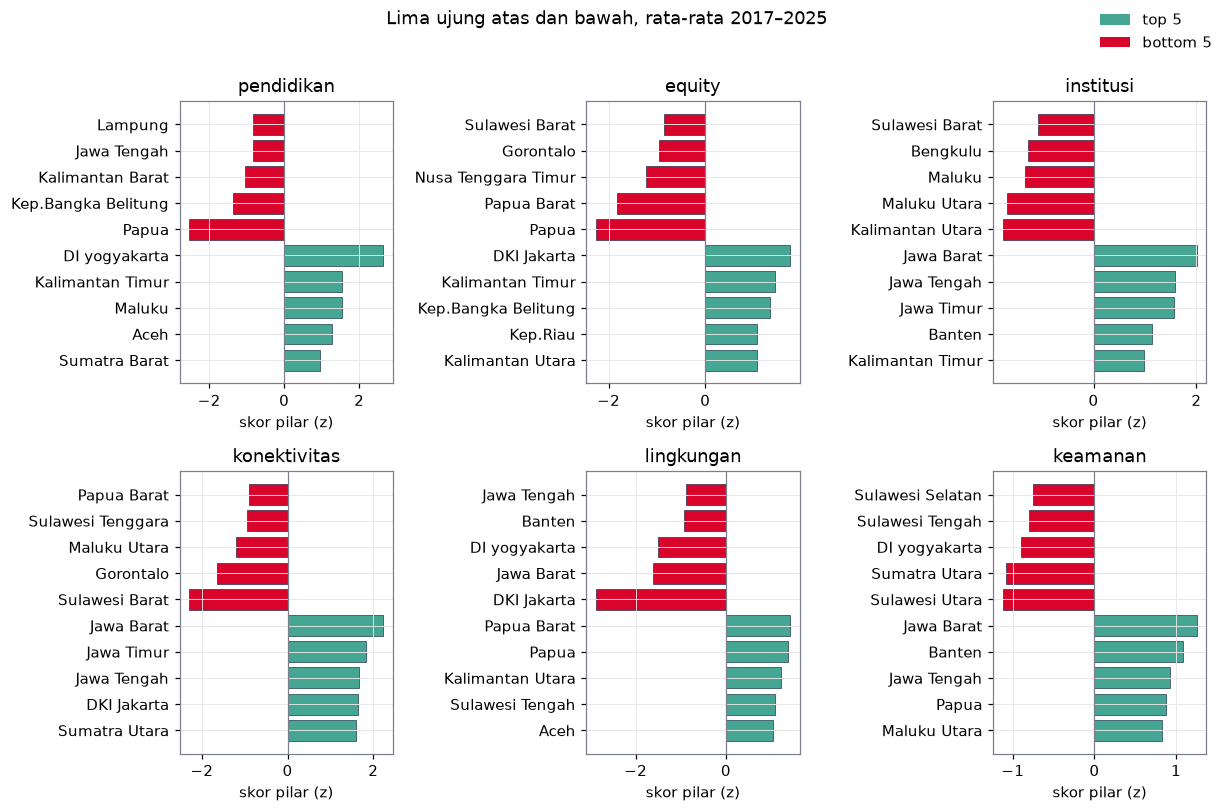

In [7]:
rows = []
for p in PILAR6:
    hi = pm.sort_values(f"pilar_{p}" if f"pilar_{p}" in pm.columns else f"m_pilar_{p}", ascending=False).head(5)
    lo = pm.sort_values(f"pilar_{p}" if f"pilar_{p}" in pm.columns else f"m_pilar_{p}", ascending=True).head(5)
    col = f"pilar_{p}" if f"pilar_{p}" in pm.columns else f"m_pilar_{p}"
    for tag, chunk in [("top5", hi), ("bot5", lo)]:
        for _, r in chunk.iterrows():
            rows.append({
                "pilar": p, "ujung": tag, "Prov": r["Pre_Prov"], "Pulau": r["Pulau"],
                "skor": r[col], "TFP_CRS": r["logtfp_it_crs"], "TFP_DRS": r["logtfp_it"],
                "IPM": r.get("ipm", np.nan), "hijau": r.get("indeks_hijau", np.nan),
                "PAD": r.get("rasio_pad", np.nan), "tk_primer": r.get("share_tk_primer", np.nan),
            })
profil = pd.DataFrame(rows)
profil.to_csv(OUT / "eda1_profil_topbot.csv", index=False)
print(profil.groupby(["pilar", "ujung"])["Prov"].apply(lambda s: ", ".join(s)).to_string())

fig, axes = plt.subplots(2, 3, figsize=(11.2, 7.2), sharey=False)
for ax, p in zip(axes.ravel(), PILAR6):
    sub = profil[profil.pilar == p].copy()
    sub["lab"] = np.where(sub.ujung == "top5", sub.Prov, sub.Prov)
    sub = pd.concat([
        sub[sub.ujung == "top5"].sort_values("skor"),
        sub[sub.ujung == "bot5"].sort_values("skor"),
    ])
    colors = [TEAL if u == "top5" else RED for u in sub.ujung]
    ax.barh(sub.Prov, sub.skor, color=colors, edgecolor=NAVY, linewidth=0.4)
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_title(p)
    ax.set_xlabel("skor pilar (z)")
fig.legend(handles=[Patch(facecolor=TEAL, label="top 5"), Patch(facecolor=RED, label="bottom 5")],
           loc="upper right", frameon=False)
fig.suptitle("Lima ujung atas dan bawah, rata-rata 2017–2025", y=1.02)
fig.tight_layout()
save(fig, "eda1_rqA_topbot_pilar.png")
plt.show()


wrote 01 Data/TFP/output/eda/eda1_rqA_profil_solow.png
wrote 01 Data/TFP/output/eda/eda1_rqA_drs_crs.png


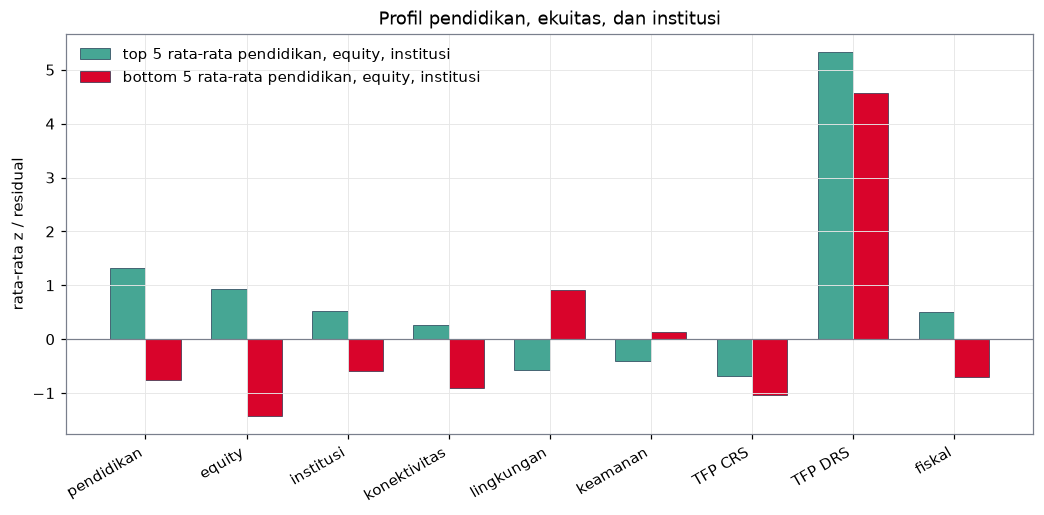

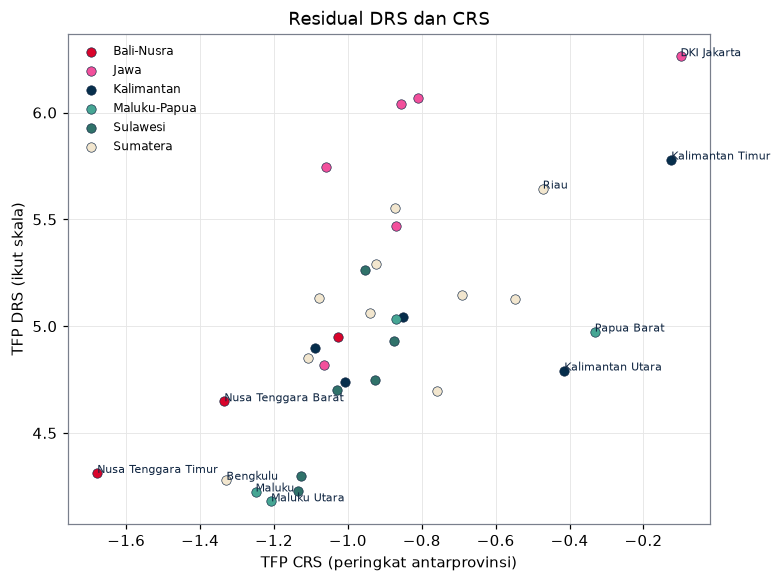

In [8]:
# top/bot idx_solow: radar-gaya grouped bar + DRS vs CRS
col_s = "idx_solow" if "idx_solow" in pm.columns else "m_idx_solow"
hi = pm.nlargest(5, col_s)
lo = pm.nsmallest(5, col_s)
metrics = [f"pilar_{p}" for p in PILAR6] + ["logtfp_it_crs", "logtfp_it", "idx_fiskal"]
metrics = [m for m in metrics if m in pm.columns]

fig, ax = plt.subplots(figsize=(9.6, 4.8))
x = np.arange(len(metrics))
w = 0.35
ax.bar(x - w/2, hi[metrics].mean().values, w, color=TEAL, label="top 5 rata-rata pendidikan, equity, institusi", edgecolor=NAVY, lw=0.4)
ax.bar(x + w/2, lo[metrics].mean().values, w, color=RED, label="bottom 5 rata-rata pendidikan, equity, institusi", edgecolor=NAVY, lw=0.4)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels([m.replace("pilar_", "").replace("logtfp_it_crs", "TFP CRS").replace("logtfp_it", "TFP DRS").replace("idx_fiskal", "fiskal")
                    for m in metrics], rotation=30, ha="right")
ax.set_ylabel("rata-rata z / residual")
ax.set_title("Profil pendidikan, ekuitas, dan institusi")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "eda1_rqA_profil_solow.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 5.4))
for pulau, g in pm.groupby("Pulau"):
    ax.scatter(g["logtfp_it_crs"], g["logtfp_it"], s=38, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, linewidth=0.4, label=pulau, zorder=3)
for _, r in pm.iterrows():
    if r["logtfp_it_crs"] >= pm["logtfp_it_crs"].quantile(0.85) or r["logtfp_it_crs"] <= pm["logtfp_it_crs"].quantile(0.15):
        ax.annotate(r["Pre_Prov"], (r["logtfp_it_crs"], r["logtfp_it"]), fontsize=7, color=NAVY)
ax.set_xlabel("TFP CRS (peringkat antarprovinsi)")
ax.set_ylabel("TFP DRS (ikut skala)")
ax.set_title("Residual DRS dan CRS")
ax.legend(frameon=False, fontsize=8, loc="best")
fig.tight_layout()
save(fig, "eda1_rqA_drs_crs.png")
plt.show()


## Lingkungan, level dan perubahan


wrote 01 Data/TFP/output/eda/eda1_rqB_hijau_kapita_diff.png
wrote 01 Data/TFP/output/eda/eda1_rqB_hijau_ekstraktif.png
wrote 01 Data/TFP/output/eda/eda1_rqB_gini_tersier.png


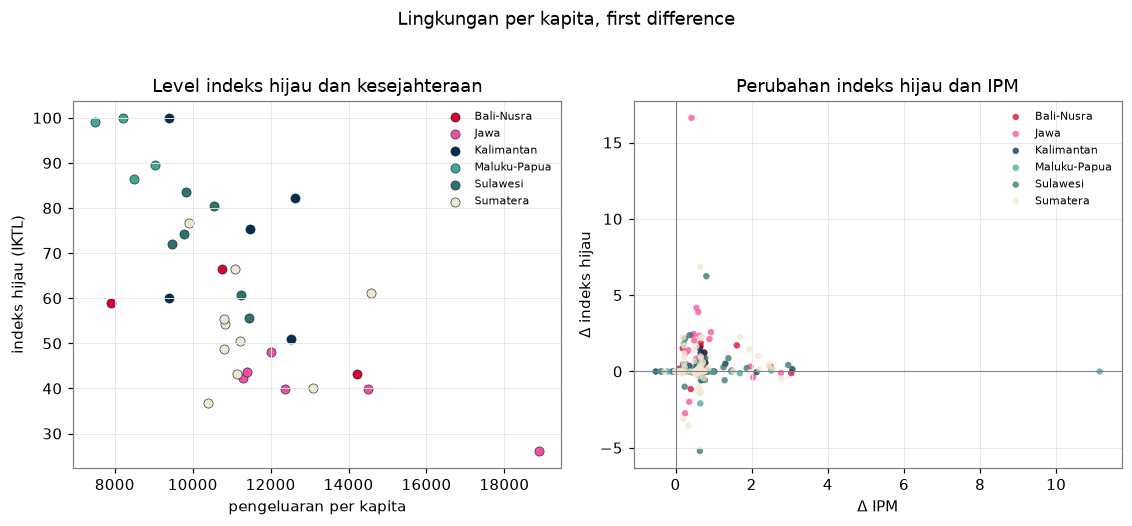

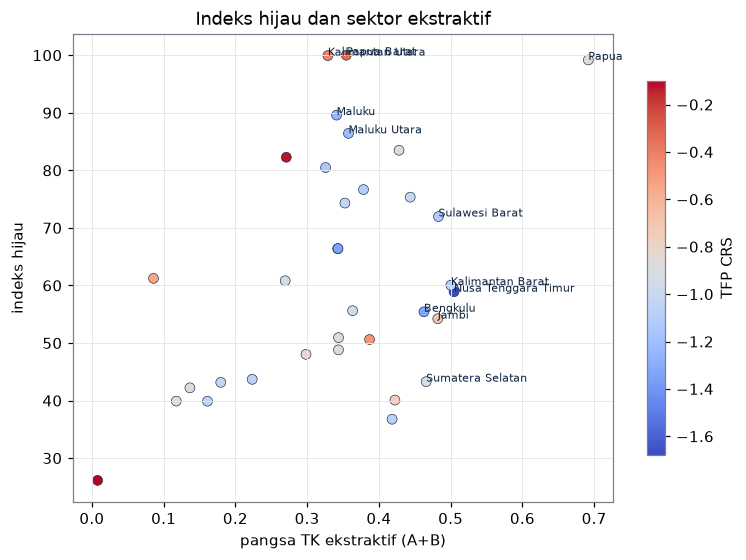

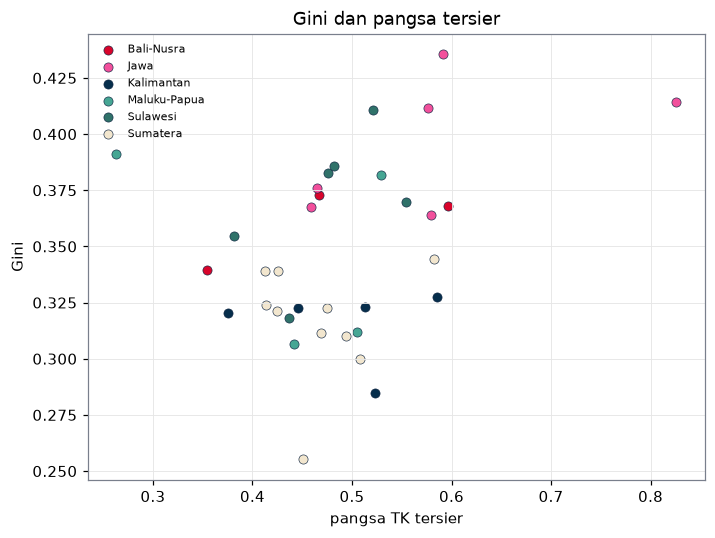

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.6))
ax = axes[0]
for pulau, g in pm.groupby("Pulau"):
    ax.scatter(g["pengeluaran_kapita"] if "pengeluaran_kapita" in g else g.get("ipm"),
               g["indeks_hijau"], s=36, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, lw=0.4, label=pulau)
ax.set_xlabel("pengeluaran per kapita" if "pengeluaran_kapita" in pm.columns else "IPM")
ax.set_ylabel("indeks hijau (IKTL)")
ax.set_title("Level indeks hijau dan kesejahteraan")
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
dd = d.dropna(subset=["indeks_hijau", "ipm"]).copy()
dd["d_hijau"] = dd.groupby("Code_Prov")["indeks_hijau"].diff()
dd["d_ipm"] = dd.groupby("Code_Prov")["ipm"].diff()
dd = dd.dropna(subset=["d_hijau", "d_ipm"])
for pulau, g in dd.groupby("Pulau"):
    ax.scatter(g["d_ipm"], g["d_hijau"], s=18, alpha=0.75, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor="none", label=pulau)
ax.axhline(0, color=GRAY, lw=0.7); ax.axvline(0, color=GRAY, lw=0.7)
ax.set_xlabel("Δ IPM")
ax.set_ylabel("Δ indeks hijau")
ax.set_title("Perubahan indeks hijau dan IPM")
ax.legend(frameon=False, fontsize=7)
fig.suptitle("Lingkungan per kapita, first difference", y=1.03)
fig.tight_layout()
save(fig, "eda1_rqB_hijau_kapita_diff.png")
plt.show()

fig, ax = plt.subplots(figsize=(7.0, 5.2))
sc = ax.scatter(pm["share_tk_ekstraktif"], pm["indeks_hijau"],
                c=pm["logtfp_it_crs"], cmap="coolwarm", s=42, edgecolor=NAVY, lw=0.4)
for _, r in pm.iterrows():
    if r["share_tk_ekstraktif"] >= pm["share_tk_ekstraktif"].quantile(0.8) or r["indeks_hijau"] >= pm["indeks_hijau"].quantile(0.85):
        ax.annotate(r["Pre_Prov"], (r["share_tk_ekstraktif"], r["indeks_hijau"]), fontsize=7, color=NAVY)
cb = fig.colorbar(sc, ax=ax, shrink=0.8)
cb.set_label("TFP CRS")
ax.set_xlabel("pangsa TK ekstraktif (A+B)")
ax.set_ylabel("indeks hijau")
ax.set_title("Indeks hijau dan sektor ekstraktif")
fig.tight_layout()
save(fig, "eda1_rqB_hijau_ekstraktif.png")
plt.show()

# gini vs tersier: tanda gini di FGLS grup positif
fig, ax = plt.subplots(figsize=(6.6, 5.0))
for pulau, g in pm.groupby("Pulau"):
    ax.scatter(g["share_tk_tersier"], g["gini"], s=36, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, lw=0.4, label=pulau)
ax.set_xlabel("pangsa TK tersier")
ax.set_ylabel("Gini")
ax.set_title("Gini dan pangsa tersier")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
save(fig, "eda1_rqB_gini_tersier.png")
plt.show()


## TK sektoral, fiskal, hilirisasi, sawit

--> Proksi sawit = investasi sektor A pada provinsi pangsa A tinggi: Riau, Kalimantan Barat, Kalimantan Tengah, Sumatera Utara, Sumatera Selatan.


wrote 01 Data/TFP/output/eda/eda1_rqD_komposisi_tk.png
wrote 01 Data/TFP/output/eda/eda1_rqD_heatmap_sektor_pilar.png


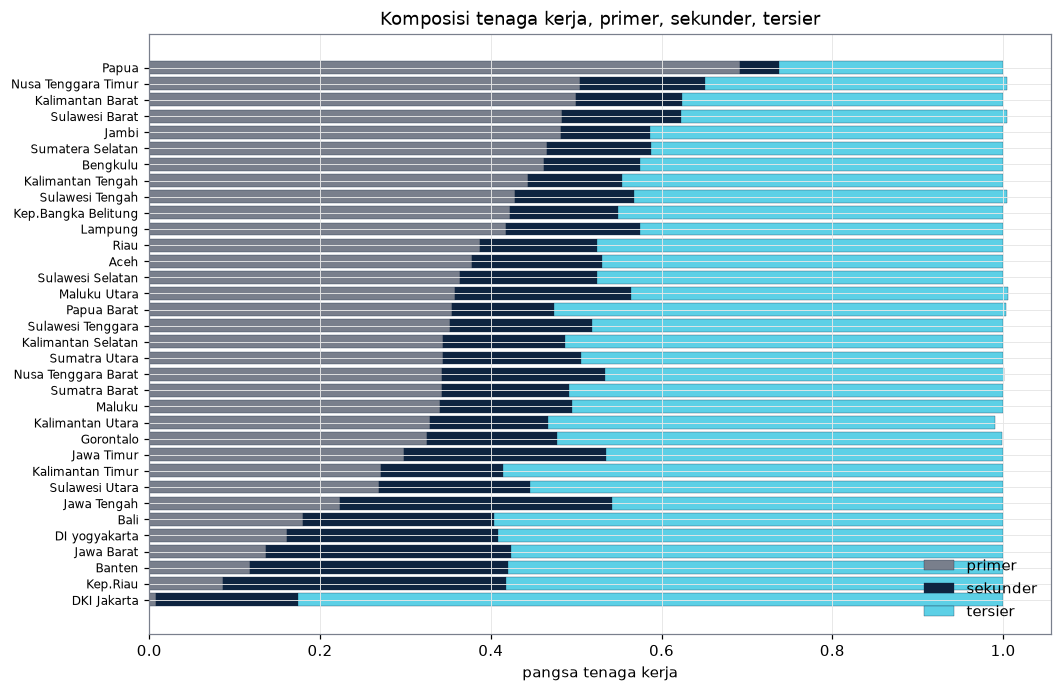

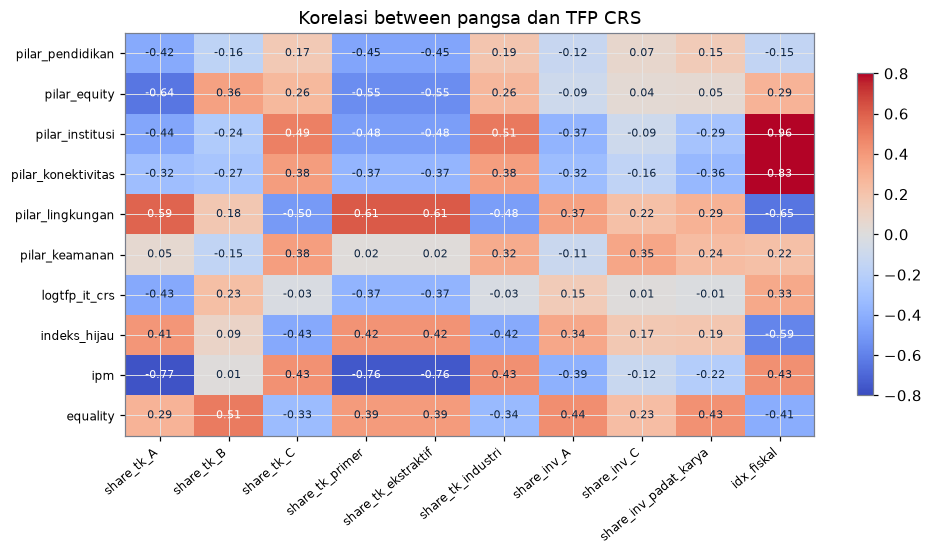

In [10]:
fig, ax = plt.subplots(figsize=(9.8, 6.4))
ordr = pm.sort_values("share_tk_primer", ascending=True)
y = np.arange(len(ordr))
left = np.zeros(len(ordr))
for name, col in [("primer", "share_tk_primer"), ("sekunder", "share_tk_sekunder"), ("tersier", "share_tk_tersier")]:
    ax.barh(y, ordr[col], left=left, color=MEGA_COLOR[name], edgecolor=NAVY, lw=0.2, label=name)
    left = left + ordr[col].values
ax.set_yticks(y)
ax.set_yticklabels(ordr.Pre_Prov, fontsize=8)
ax.set_xlabel("pangsa tenaga kerja")
ax.set_title("Komposisi tenaga kerja, primer, sekunder, tersier")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save(fig, "eda1_rqD_komposisi_tk.png")
plt.show()

heat_x = [c for c in ["share_tk_A", "share_tk_B", "share_tk_C", "share_tk_primer",
                      "share_tk_ekstraktif", "share_tk_industri", "share_inv_A",
                      "share_inv_C", "share_inv_padat_karya", "idx_fiskal"] if c in pm.columns]
heat_y = [c for c in [f"pilar_{p}" for p in PILAR6] + ["logtfp_it_crs", "indeks_hijau", "ipm", "equality"] if c in pm.columns]
H = pm[heat_x + heat_y].corr().loc[heat_y, heat_x]
fig, ax = plt.subplots(figsize=(9.2, 5.2))
im = ax.imshow(H.values, cmap="coolwarm", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(heat_x))); ax.set_xticklabels(heat_x, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(heat_y))); ax.set_yticklabels(heat_y, fontsize=8)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(H.values[i, j]) > 0.45 else NAVY)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Korelasi between pangsa dan TFP CRS")
fig.tight_layout()
save(fig, "eda1_rqD_heatmap_sektor_pilar.png")
plt.show()


wrote 01 Data/TFP/output/eda/eda1_rqD_dominan_hilir_sawit.png
wrote 01 Data/TFP/output/eda/eda1_rqD_fiskal_pemerataan.png


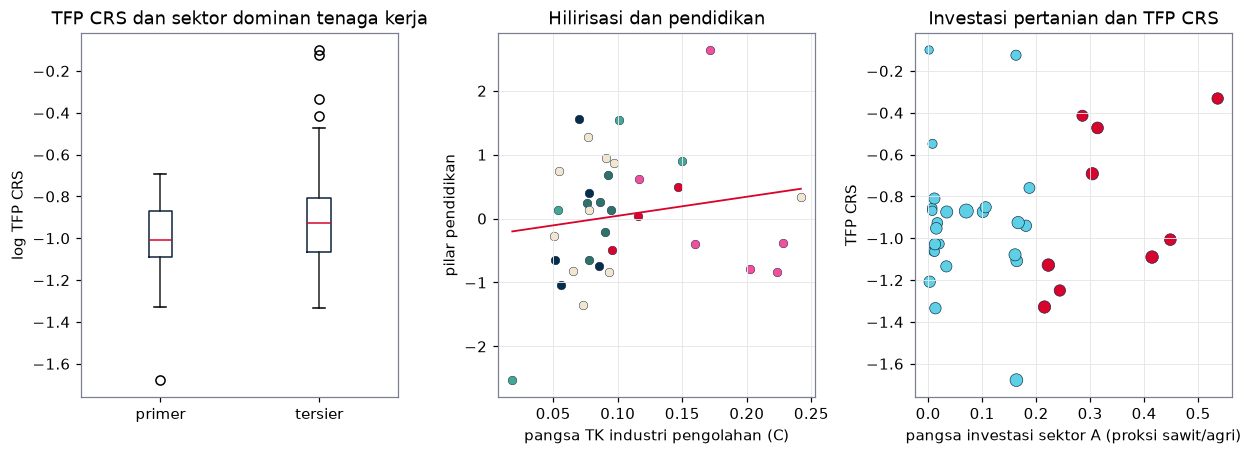

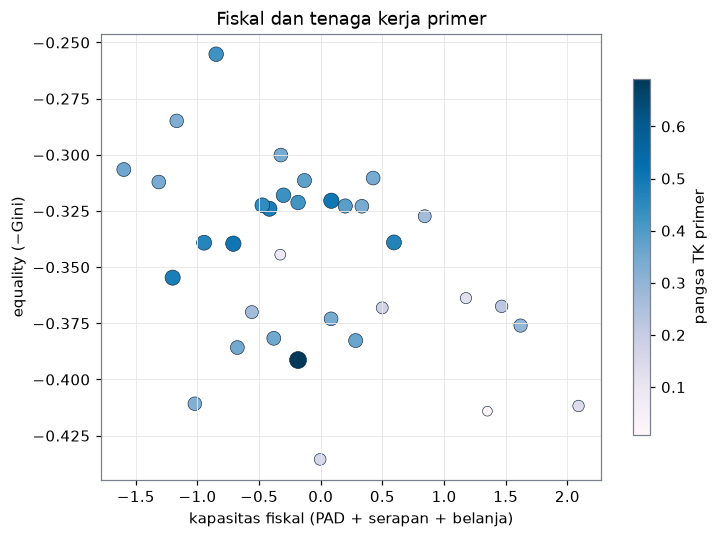

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 4.4))
ax = axes[0]
pm.boxplot(column="logtfp_it_crs", by="dominan_tk", ax=ax, grid=False,
           boxprops=dict(color=NAVY), medianprops=dict(color=RED))
ax.set_title("TFP CRS dan sektor dominan tenaga kerja")
ax.set_xlabel(""); ax.set_ylabel("log TFP CRS")
plt.suptitle("")
ax = axes[1]
for pulau, g in pm.groupby("Pulau"):
    ax.scatter(g["share_tk_C"], g["pilar_pendidikan"], s=32, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, lw=0.3)
z = np.polyfit(pm["share_tk_C"].fillna(0), pm["pilar_pendidikan"].fillna(0), 1)
xx = np.linspace(pm["share_tk_C"].min(), pm["share_tk_C"].max(), 40)
ax.plot(xx, np.polyval(z, xx), color=RED, lw=1.2)
ax.set_xlabel("pangsa TK industri pengolahan (C)")
ax.set_ylabel("pilar pendidikan")
ax.set_title("Hilirisasi dan pendidikan")
ax = axes[2]
sc = ax.scatter(pm["share_inv_A"], pm["logtfp_it_crs"],
                s=30 + 80 * pm["share_tk_A"].fillna(0),
                c=np.where(pm.get("d_sawit", 0) == 1, RED, CYAN),
                edgecolor=NAVY, lw=0.4)
ax.set_xlabel("pangsa investasi sektor A (proksi sawit/agri)")
ax.set_ylabel("TFP CRS")
ax.set_title("Investasi pertanian dan TFP CRS")
fig.tight_layout()
save(fig, "eda1_rqD_dominan_hilir_sawit.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.8, 5.0))
sc = ax.scatter(pm["idx_fiskal"], pm["equality"] if "equality" in pm.columns else -pm["gini"],
                s=40 + 120 * pm["share_tk_primer"].fillna(0),
                c=pm["share_tk_primer"], cmap="PuBu", edgecolor=NAVY, lw=0.4)
cb = fig.colorbar(sc, ax=ax, shrink=0.8); cb.set_label("pangsa TK primer")
ax.set_xlabel("kapasitas fiskal (PAD + serapan + belanja)")
ax.set_ylabel("equality (−Gini)")
ax.set_title("Fiskal dan tenaga kerja primer")
fig.tight_layout()
save(fig, "eda1_rqD_fiskal_pemerataan.png")
plt.show()


## FGLS grup

--> `xtgls` per penyusun z, spesifikasi yang sama dengan Determinan TFP.


wrote 01 Data/TFP/output/eda/eda1_rqE_solow_vs_hard.png
wrote 01 Data/TFP/output/eda/eda1_rqE_tfp_pilar.png
wrote 01 Data/TFP/output/eda/eda1_fgls_grup_jumlah.png
wrote 01 Data/TFP/output/eda/eda1_rqD_fgls_sektor.png


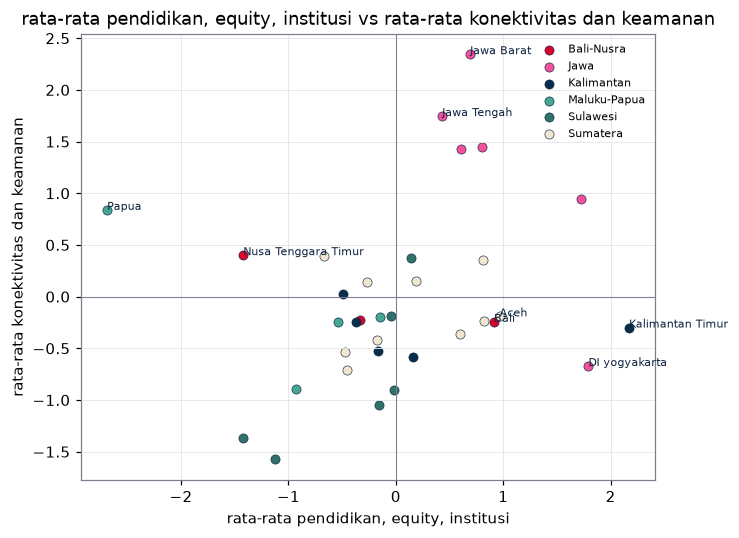

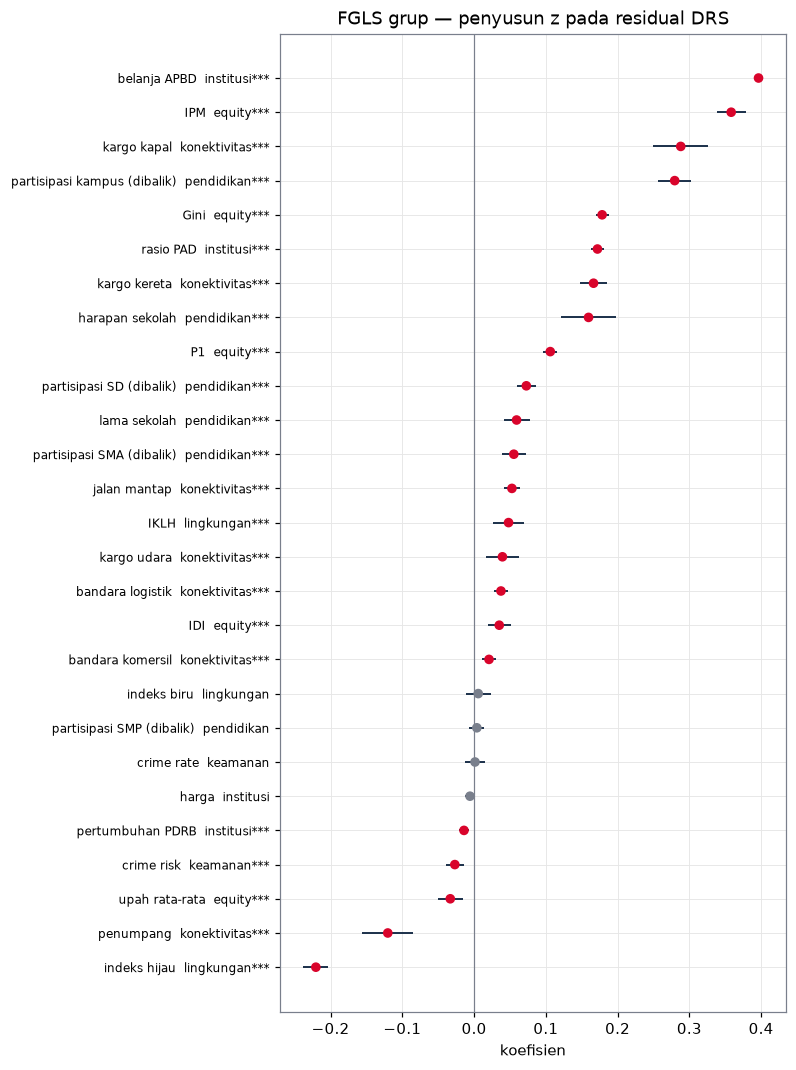

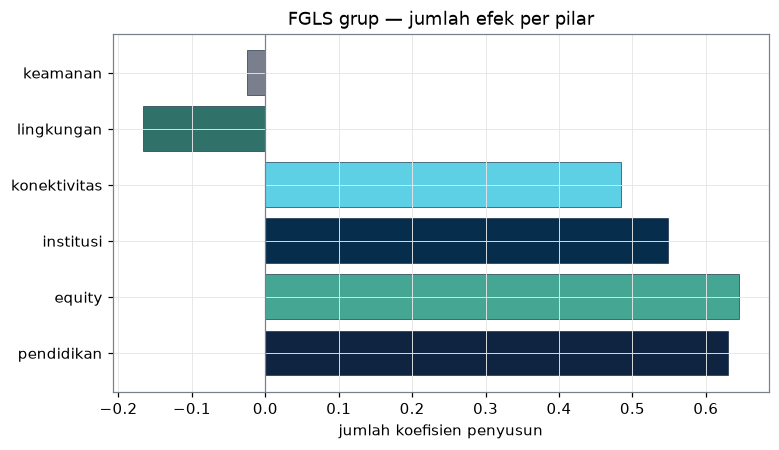

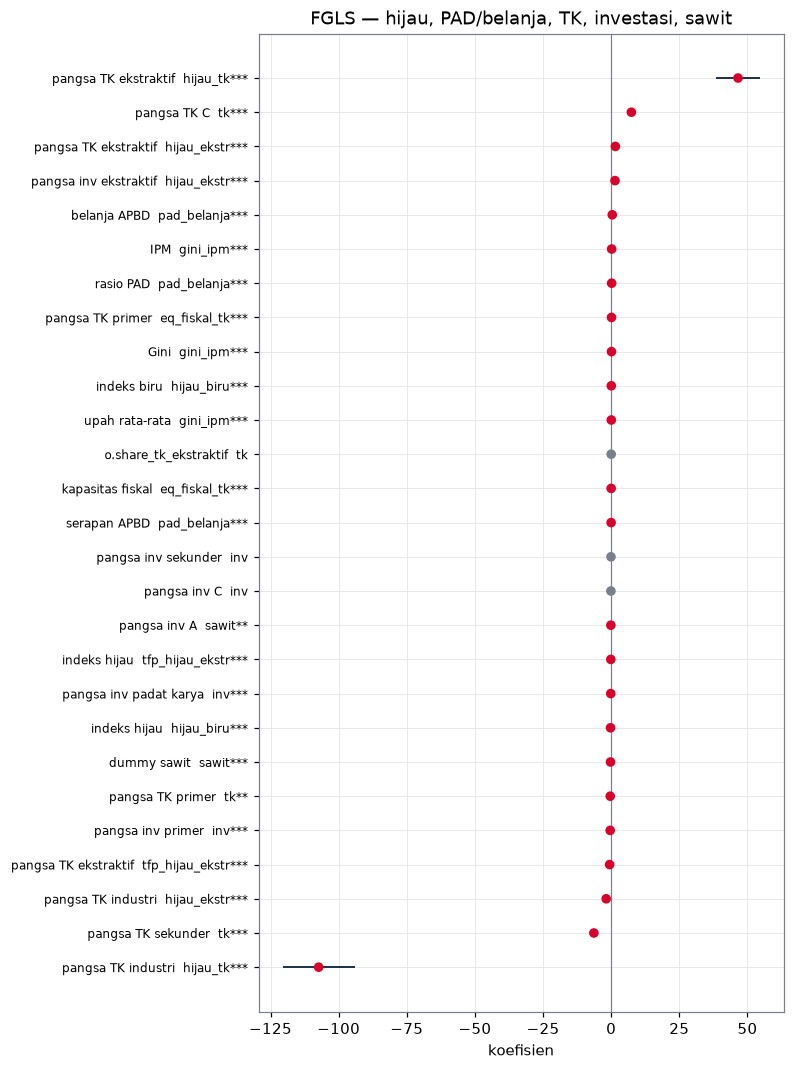

In [12]:
fig, ax = plt.subplots(figsize=(6.8, 5.0))
for pulau, g in pm.groupby("Pulau"):
    ax.scatter(g["idx_solow"], g["idx_hard"], s=36, color=PULAU_COLOR.get(pulau, GRAY),
               edgecolor=NAVY, lw=0.4, label=pulau)
for _, r in pm.iterrows():
    if abs(r["idx_solow"] - r["idx_hard"]) > 1.1:
        ax.annotate(r["Pre_Prov"], (r["idx_solow"], r["idx_hard"]), fontsize=7, color=NAVY)
ax.axhline(0, color=GRAY, lw=0.7); ax.axvline(0, color=GRAY, lw=0.7)
ax.set_xlabel("rata-rata pendidikan, equity, institusi")
ax.set_ylabel("rata-rata konektivitas dan keamanan")
ax.set_title("rata-rata pendidikan, equity, institusi vs rata-rata konektivitas dan keamanan")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
save(fig, "eda1_rqE_solow_vs_hard.png")
plt.show()

VARLAB = {
    "z_ln_lama_sekolah_mean": "lama sekolah",
    "z_ln_lama_sekolah_harapan": "harapan sekolah",
    "z_db_sd": "partisipasi SD (dibalik)",
    "z_db_smp": "partisipasi SMP (dibalik)",
    "z_db_sma": "partisipasi SMA (dibalik)",
    "z_db_kampus": "partisipasi kampus (dibalik)",
    "z_ln_p1": "P1",
    "z_ln_ipm": "IPM",
    "z_gini": "Gini",
    "z_ln_upah_rata": "upah rata-rata",
    "z_ln_indeks_demokrasi": "IDI",
    "z_price": "harga",
    "z_ln_rasio_pad": "rasio PAD",
    "z_ln_pertumbuhan_pdrb_adhb": "pertumbuhan PDRB",
    "z_ln_apbd_belanja": "belanja APBD",
    "z_ln_apbd_serapan": "serapan APBD",
    "z_ln_jalan_mantap": "jalan mantap",
    "z_ln_kargo_udara": "kargo udara",
    "z_ln_kargo_kapal": "kargo kapal",
    "z_ln_kargo_kereta": "kargo kereta",
    "z_ln_penumpang_total": "penumpang",
    "z_ln_airport_logistik": "bandara logistik",
    "z_ln_airport_komersil": "bandara komersil",
    "z_ln_indeks_lingkungan": "IKLH",
    "z_ln_indeks_hijau": "indeks hijau",
    "z_ln_indeks_biru": "indeks biru",
    "z_ln_crime_risk": "crime risk",
    "z_ln_crime_rate": "crime rate",
    "share_tk_primer": "pangsa TK primer",
    "share_tk_sekunder": "pangsa TK sekunder",
    "share_tk_ekstraktif": "pangsa TK ekstraktif",
    "share_tk_industri": "pangsa TK industri",
    "share_tk_C": "pangsa TK C",
    "share_inv_primer": "pangsa inv primer",
    "share_inv_sekunder": "pangsa inv sekunder",
    "share_inv_C": "pangsa inv C",
    "share_inv_padat_karya": "pangsa inv padat karya",
    "share_inv_A": "pangsa inv A",
    "share_inv_ekstraktif": "pangsa inv ekstraktif",
    "d_sawit": "dummy sawit",
    "idx_fiskal": "kapasitas fiskal",
    "equality": "equality",
}

def _lab(v):
    return VARLAB.get(v, v.replace("z_ln_", "").replace("z_", ""))

coef_path = EVAL / "eval1_coef.csv"
if coef_path.exists():
    c = pd.read_csv(coef_path)

    def coefplot(sub, title, fname):
        if sub.empty:
            print("kosong", title)
            return
        sub = sub.copy()
        sub["lo"] = sub.b - 1.96 * sub.se
        sub["hi"] = sub.b + 1.96 * sub.se
        sub = sub.sort_values("b")
        fig, ax = plt.subplots(figsize=(7.4, max(3.2, 0.32 * len(sub) + 1.2)))
        y = np.arange(len(sub))
        ax.hlines(y, sub.lo, sub.hi, color=NAVY, lw=1.2)
        ax.scatter(sub.b, y, color=np.where(sub.p < 0.05, RED, GRAY), zorder=3, s=28)
        ax.axvline(0, color=GRAY, lw=0.8)
        ax.set_yticks(y)
        ax.set_yticklabels([f"{_lab(r.var)}  {r.model.replace('FGLS_', '')}{stars(r.p)}"
                            for r in sub.itertuples()], fontsize=8)
        ax.set_xlabel("koefisien")
        ax.set_title(title)
        fig.tight_layout()
        save(fig, fname)
        plt.show()

    grup = ["FGLS_pendidikan", "FGLS_equity", "FGLS_institusi",
            "FGLS_konektivitas", "FGLS_lingkungan", "FGLS_keamanan"]
    g = c[c.model.isin(grup)].copy()
    coefplot(g, "FGLS grup — penyusun z pada residual DRS", "eda1_rqE_tfp_pilar.png")

    jum = g.groupby("model", as_index=False)["b"].sum()
    jum["pilar"] = jum.model.str.replace("FGLS_", "", regex=False)
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    order = ["pendidikan", "equity", "institusi", "konektivitas", "lingkungan", "keamanan"]
    jum = jum.set_index("pilar").reindex(order).reset_index()
    cols = [PILAR_COLOR.get(p, NAVY) for p in jum.pilar]
    ax.barh(jum.pilar, jum.b, color=cols, edgecolor=NAVY, lw=0.4)
    ax.axvline(0, color=GRAY, lw=0.8)
    ax.set_xlabel("jumlah koefisien penyusun")
    ax.set_title("FGLS grup — jumlah efek per pilar")
    fig.tight_layout()
    save(fig, "eda1_fgls_grup_jumlah.png")
    plt.show()

    ekstra = c[c.model.isin([
        "FGLS_hijau_biru", "FGLS_hijau_ekstr", "FGLS_tfp_hijau_ekstr",
        "FGLS_gini_ipm", "FGLS_pad_belanja", "FGLS_tk", "FGLS_inv",
        "FGLS_sawit", "FGLS_hijau_tk", "FGLS_eq_fiskal_tk",
    ])]
    coefplot(ekstra, "FGLS — hijau, PAD/belanja, TK, investasi, sawit", "eda1_rqD_fgls_sektor.png")
else:
    print("eval1_coef.csv belum ada — jalankan: do \"02 Code/TFP/eval1.do\"")
